[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/myway0101/see-read-explain-dl/blob/main/notebooks/ch04_transfer_learning.ipynb)

# 4장 대표 CNN 아키텍처와 전이학습 — 실습 노트북
『딥러닝 응용 — 보고, 읽고, 설명하는 딥러닝』

4장 본문에 나오는 코드를 순서대로 실행해 봅니다. 위에서부터 차례로 실행하세요.
- 4.5 특성 추출: ImageNet으로 학습한 VGG16 + 새 분류기
- 4.6 데이터 증강: `ImageDataGenerator`
- 4.7 미세조정: VGG16의 마지막 블록까지 다시 학습
- 실습: 미세조정 범위와 학습률 바꿔 보기

> **GPU를 꼭 켜고 실행하세요.** 메뉴 [런타임] → [런타임 유형 변경]에서 하드웨어 가속기를 **T4 GPU**로 고릅니다. CPU로는 한 번 학습하는 데 한 시간이 넘게 걸릴 수 있습니다.

## 준비

In [1]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import os

from tensorflow.keras import Model
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten,GlobalMaxPool2D, GlobalAveragePooling2D
from tensorflow.keras.applications import VGG16
from tensorflow.keras.preprocessing.image import ImageDataGenerator

%config InlineBackend.figure_format = 'retina'
tf.keras.utils.set_random_seed(42)
print("TensorFlow", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

TensorFlow 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 4.5 특성 추출
### ImageNet으로 학습한 VGG16 불러오기
`include_top=False`는 맨 위의 완전연결층(1,000개 클래스 분류기)을 빼고 합성곱 부분만 가져온다는 뜻입니다.

In [2]:
model = VGG16(include_top=False,
                 weights="imagenet")

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


In [3]:
model.summary()

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, None, None, 3)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, None, None, 64) │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, None, None, 64) │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, None, None, 64) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, None, None,     │        73,856 │
│                                 │ 128)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, None, None,     │       147,584 │
│                                 │ 128)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, None, None,     │             0 │
│                                 │ 128)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, None, None,     │       295,168 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, None, None,     │       590,080 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, None, None,     │       590,080 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, None, None,     │             0 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, None, None,     │     1,180,160 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, None, None,     │     2,359,808 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, None, None,     │     2,359,808 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, None, None,     │             0 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, None, None,     │     2,359,808 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, None, None,     │     2,359,808 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, None, None,     │     2,359,808 │
│                                 │ 512)                   │             

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 14,714,688 (56.13 MB)

 Non-trainable params: 0 (0.00 B)

### 합성곱 부분은 고정하고 새 분류기 붙이기

In [4]:
model.trainable = False
model = Sequential([model,
                    GlobalAveragePooling2D(),
                    Dense(2, activation='softmax')])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, None, None,     │    14,714,688 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2)              │         1,026 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,715,714 (56.14 MB)

 Trainable params: 1,026 (4.01 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [5]:
model.compile(loss='binary_crossentropy',
              optimizer='adam',
              metrics=['accuracy'])

### 전역 평균 풀링(GlobalAveragePooling) 직접 확인하기
특성 맵 3장(각 3×3)에 전역 평균 풀링과 전역 최대 풀링을 적용해 봅니다. 평균 풀링은 9칸의 **평균**, 최대 풀링은 **최댓값**을 냅니다.

In [6]:
fmap = np.zeros((1, 3, 3, 3), dtype='float32')        # (배치, 높이, 너비, 채널)
fmap[0, :, :, 0] = [[1, 2, 0], [1, 0, 0], [0, 0, 0]]
fmap[0, :, :, 1] = [[0, 3, 1], [2, 0, 1], [0, 1, 1]]
fmap[0, :, :, 2] = [[5, 0, 0], [0, 0, 0], [0, 0, 4]]
print("GlobalAveragePooling2D:", GlobalAveragePooling2D()(fmap).numpy())
print("GlobalMaxPool2D       :", GlobalMaxPool2D()(fmap).numpy())

GlobalAveragePooling2D: [[0.44444445 1.         1.        ]]
GlobalMaxPool2D       : [[2. 3. 5.]]


### 개/고양이 데이터 내려받기
마이크로소프트가 공개한 개·고양이 사진 25,000장(Kaggle Dogs vs. Cats 대회 데이터)을 내려받아, 고양이와 개를 각각 1,500장씩 골라 **학습 1,000장 + 검증 500장**으로 나눕니다. 그래서 학습 2,000장, 검증 1,000장이 됩니다. 원본에는 열리지 않는 사진이 몇 장 섞여 있어 열어 보고 괜찮은 것만 씁니다.

In [7]:
import zipfile, shutil
from PIL import Image

_URL = 'https://download.microsoft.com/download/3/E/1/3E1C3F21-ECDB-4869-8368-6DEBA77B919F/kagglecatsanddogs_5340.zip'
path_to_zip = tf.keras.utils.get_file('kagglecatsanddogs.zip', origin=_URL, extract=False)  # 약 800MB
PATH = os.path.dirname(path_to_zip)

with zipfile.ZipFile(path_to_zip, 'r') as zip_ref:
    zip_ref.extractall(PATH)

src = os.path.join(PATH, 'PetImages')                    # Cat/0.jpg ~ 12499.jpg, Dog/0.jpg ~ 12499.jpg
base = os.path.join(PATH, 'cats_and_dogs_filtered')
for cls, name in [('Cat', 'cats'), ('Dog', 'dogs')]:
    files = []
    for i in range(12500):
        p = os.path.join(src, cls, f'{i}.jpg')
        try:
            with Image.open(p) as im:
                im.verify()                               # 깨진 사진은 건너뛴다
            files.append(p)
        except Exception:
            pass
        if len(files) == 1500:
            break
    for split, part in [('train', files[:1000]), ('validation', files[1000:])]:
        d = os.path.join(base, split, name)
        os.makedirs(d, exist_ok=True)
        for p in part:
            shutil.copy(p, d)

train_dir = os.path.join(base, 'train')
valid_dir = os.path.join(base, 'validation')

824887076/824887076 ━━━━━━━━━━━━━━━━━━━━ 9s 0us/step


In [8]:
for d in [train_dir, valid_dir]:
    for c in sorted(os.listdir(d)):
        print(d.split('/')[-1], c, len(os.listdir(os.path.join(d, c))))

train cats 1000
train dogs 1000
validation cats 500
validation dogs 500


In [9]:
BATCH_SIZE = 32
image_height = 160
image_width = 160

## 4.6 데이터 증강
학습할 때마다 이미지를 조금씩 회전·이동·전단·확대해서 넣습니다. 검증 데이터에는 증강을 하지 않고 크기만 0~1로 맞춥니다.

In [10]:
# 훈련 데이터에 대한 ImageDataGenerator 인스턴스를 생성합니다.
# 이는 훈련 중에 이미지에 다양한 변형을 적용합니다.
train = ImageDataGenerator(
    rescale=1./255,  # 픽셀 값을 [0, 1] 범위로 조정합니다.
    rotation_range=10,  # 이미지를 -10도~+10도 범위에서 무작위로 회전합니다.
    width_shift_range=0.1,  # 이미지를 너비의 최대 10%까지 무작위로 가로로 이동합니다.
    height_shift_range=0.1,  # 이미지를 높이의 최대 10%까지 무작위로 세로로 이동합니다.
    shear_range=0.1,  # 무작위 전단 변형을 적용합니다.
    zoom_range=0.1  # 이미지를 최대 10%까지 무작위로 확대 또는 축소합니다.
)

# 훈련 데이터셋에 대한 데이터 생성기를 만듭니다.
# 이 생성기는 지정된 디렉토리에서 이미지를 로드하고 증강을 적용합니다.
train_generator = train.flow_from_directory(
    train_dir,  # 훈련 이미지가 포함된 디렉토리 (각 클래스에 대한 하위 디렉토리로 구성됨)
    target_size=(image_height, image_width),  # 이미지를 지정된 크기로 조정합니다.
    color_mode="rgb",  # RGB 색상 모드로 이미지를 로드합니다.
    batch_size=BATCH_SIZE,  # 각 배치에 로드할 이미지 수입니다.
    seed=1,  # 재현성을 위해 난수 시드를 설정합니다.
    shuffle=True,  # 각 에포크 전에 이미지를 섞습니다.
    class_mode="categorical"  # 범주형 분류를 위한 원-핫 인코딩 레이블을 생성합니다.
)

Found 2000 images belonging to 2 classes.


In [11]:
valid = ImageDataGenerator(rescale=1.0/255.0)
valid_generator = valid.flow_from_directory(valid_dir,
                                                    target_size=(image_height, image_width),
                                                    color_mode="rgb",
                                                    batch_size=BATCH_SIZE,
                                                    seed=7,
                                                    shuffle=True,
                                                    class_mode="categorical"
                                                    )
print(train_generator.class_indices)

Found 1000 images belonging to 2 classes.
{'cats': 0, 'dogs': 1}


### 증강된 이미지 눈으로 보기
같은 고양이 사진 한 장에 변환을 하나씩 크게 적용해 봅니다. (눈에 잘 보이도록 범위를 실제 학습보다 크게 잡았습니다.)

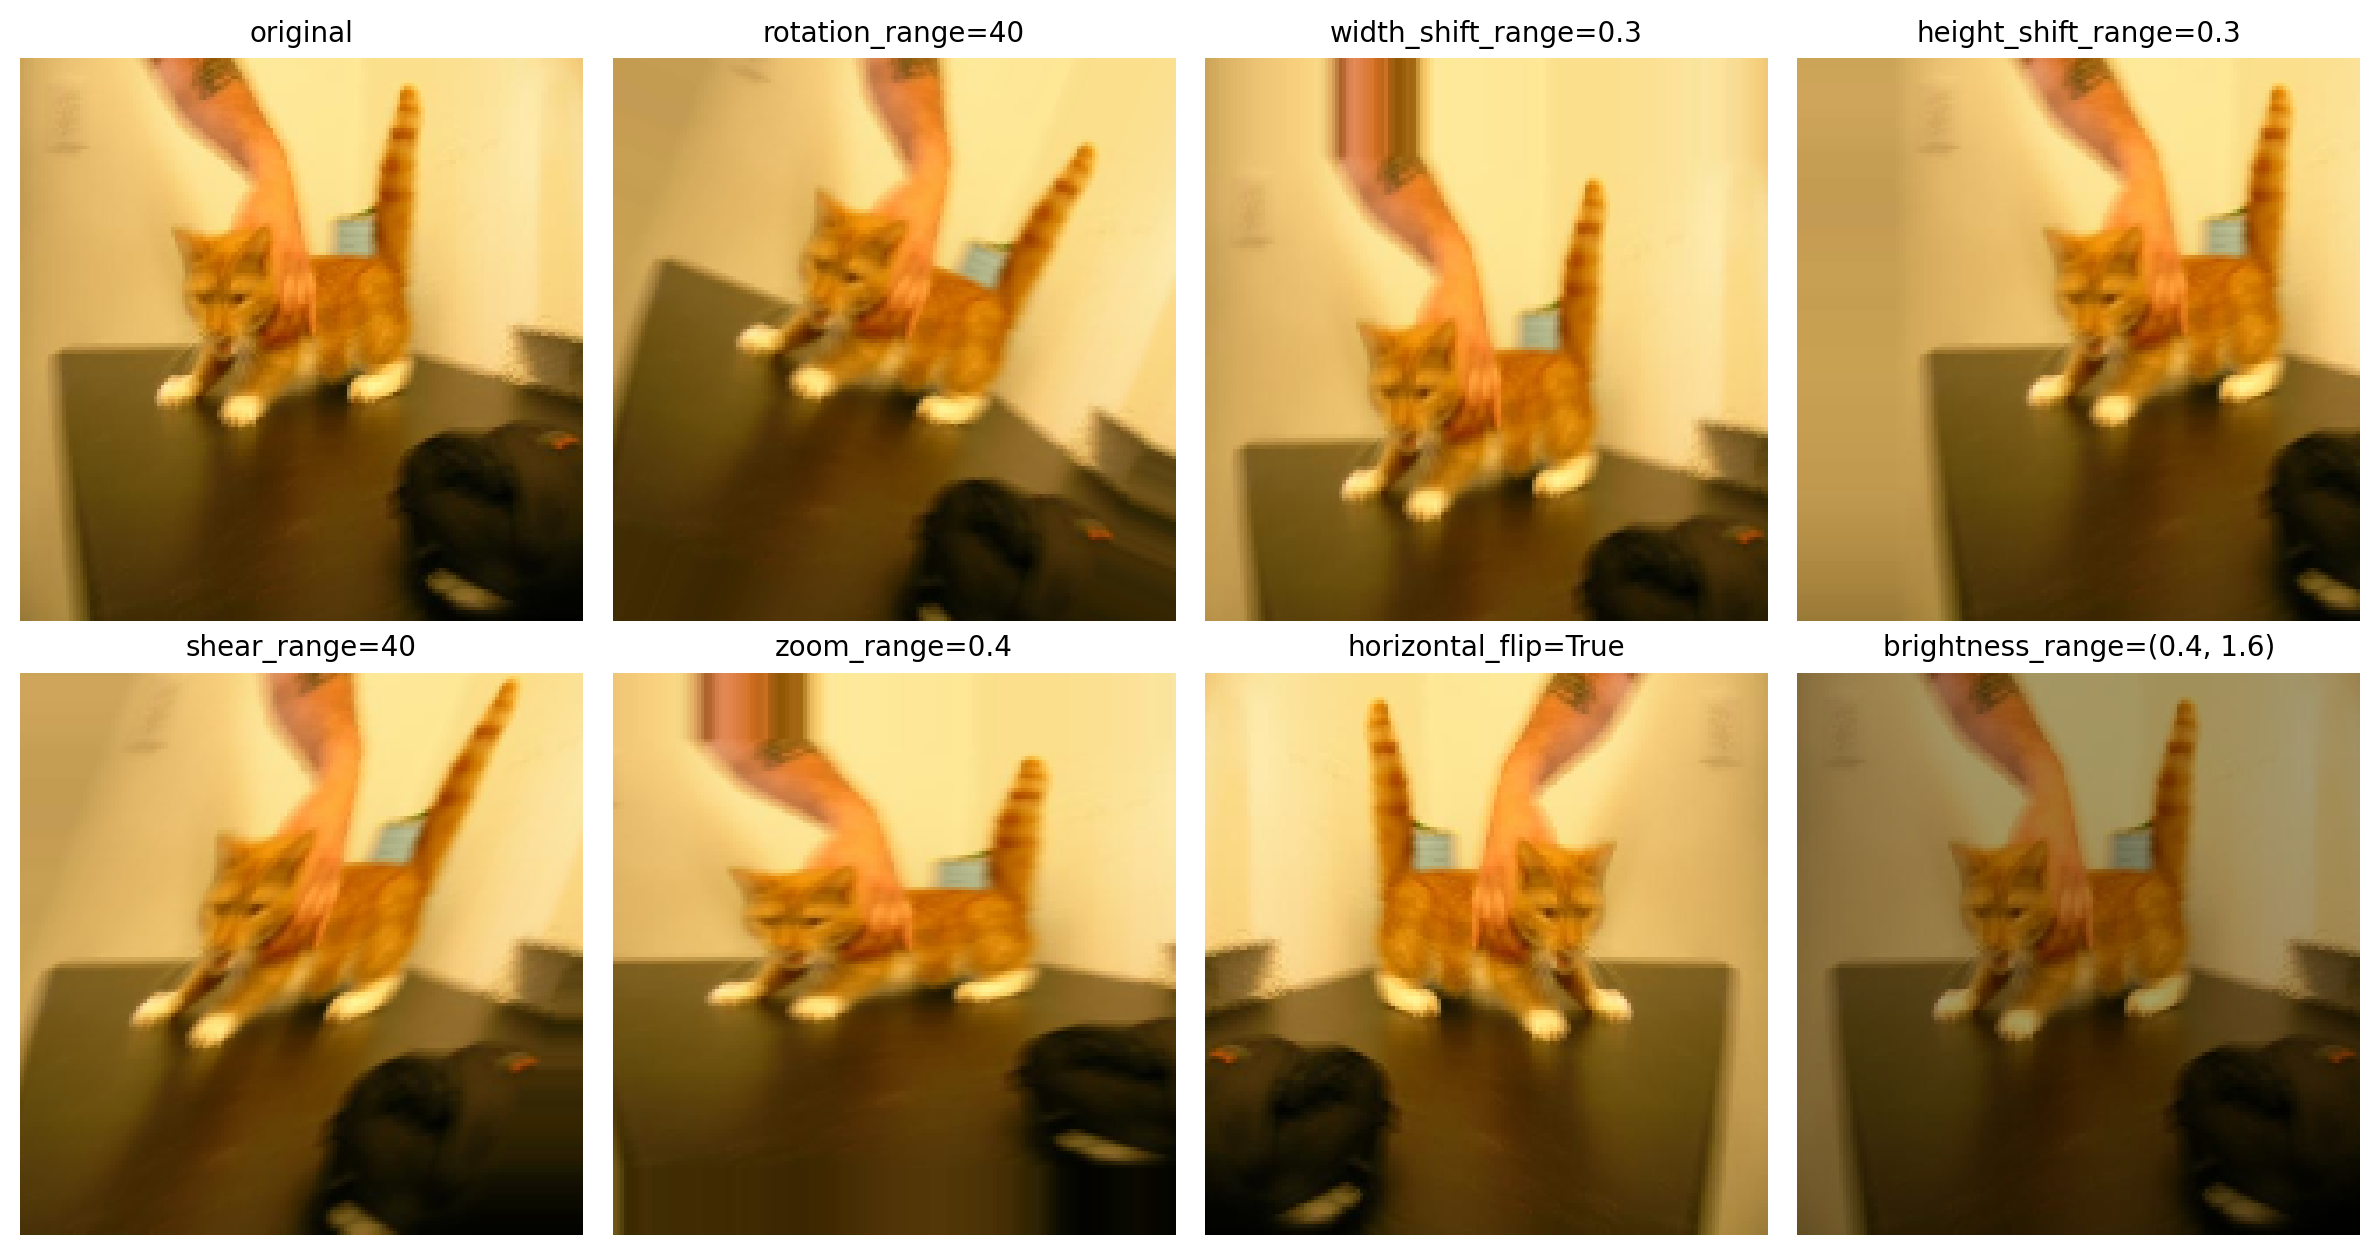

In [12]:
from tensorflow.keras.preprocessing.image import load_img, img_to_array
sample_path = os.path.join(train_dir, 'cats', sorted(os.listdir(os.path.join(train_dir, 'cats')))[0])
img = img_to_array(load_img(sample_path, target_size=(image_height, image_width)))

demo = {'original': ImageDataGenerator(),
        'rotation_range=40': ImageDataGenerator(rotation_range=40),
        'width_shift_range=0.3': ImageDataGenerator(width_shift_range=0.3),
        'height_shift_range=0.3': ImageDataGenerator(height_shift_range=0.3),
        'shear_range=40': ImageDataGenerator(shear_range=40),
        'zoom_range=0.4': ImageDataGenerator(zoom_range=0.4),
        'horizontal_flip=True': ImageDataGenerator(horizontal_flip=True),
        'brightness_range=(0.4, 1.6)': ImageDataGenerator(brightness_range=(0.4, 1.6))}
fig, axes = plt.subplots(2, 4, figsize=(12, 6.4))
for ax, (name, gen) in zip(axes.flat, demo.items()):
    out = img if name == 'original' else gen.random_transform(img, seed=5)
    ax.imshow(np.clip(out, 0, 255).astype('uint8')); ax.set_title(name, fontsize=10); ax.axis('off')
plt.tight_layout(); plt.show()

### 분류기만 학습하기 (특성 추출)

In [13]:
history=model.fit(train_generator,
          epochs=10,
          validation_data=valid_generator,
          verbose=2)

Epoch 1/10
63/63 - 30s - 476ms/step - accuracy: 0.6520 - loss: 0.6590 - val_accuracy: 0.7480 - val_loss: 0.6137
Epoch 2/10
63/63 - 20s - 313ms/step - accuracy: 0.7660 - loss: 0.5984 - val_accuracy: 0.7750 - val_loss: 0.5618
Epoch 3/10
63/63 - 19s - 304ms/step - accuracy: 0.7955 - loss: 0.5539 - val_accuracy: 0.8150 - val_loss: 0.5177
Epoch 4/10
63/63 - 19s - 304ms/step - accuracy: 0.8035 - loss: 0.5209 - val_accuracy: 0.8220 - val_loss: 0.4861
Epoch 5/10
63/63 - 19s - 301ms/step - accuracy: 0.8215 - loss: 0.4930 - val_accuracy: 0.8260 - val_loss: 0.4611
Epoch 6/10
63/63 - 19s - 298ms/step - accuracy: 0.8215 - loss: 0.4779 - val_accuracy: 0.8340 - val_loss: 0.4402
Epoch 7/10
63/63 - 19s - 303ms/step - accuracy: 0.8330 - loss: 0.4580 - val_accuracy: 0.8390 - val_loss: 0.4239
Epoch 8/10
63/63 - 19s - 308ms/step - accuracy: 0.8350 - loss: 0.4423 - val_accuracy: 0.8440 - val_loss: 0.4125
Epoch 9/10
63/63 - 20s - 315ms/step - accuracy: 0.8440 - loss: 0.4277 - val_accuracy: 0.8510 - val_loss:

Text(0.5, 1.0, 'loss')

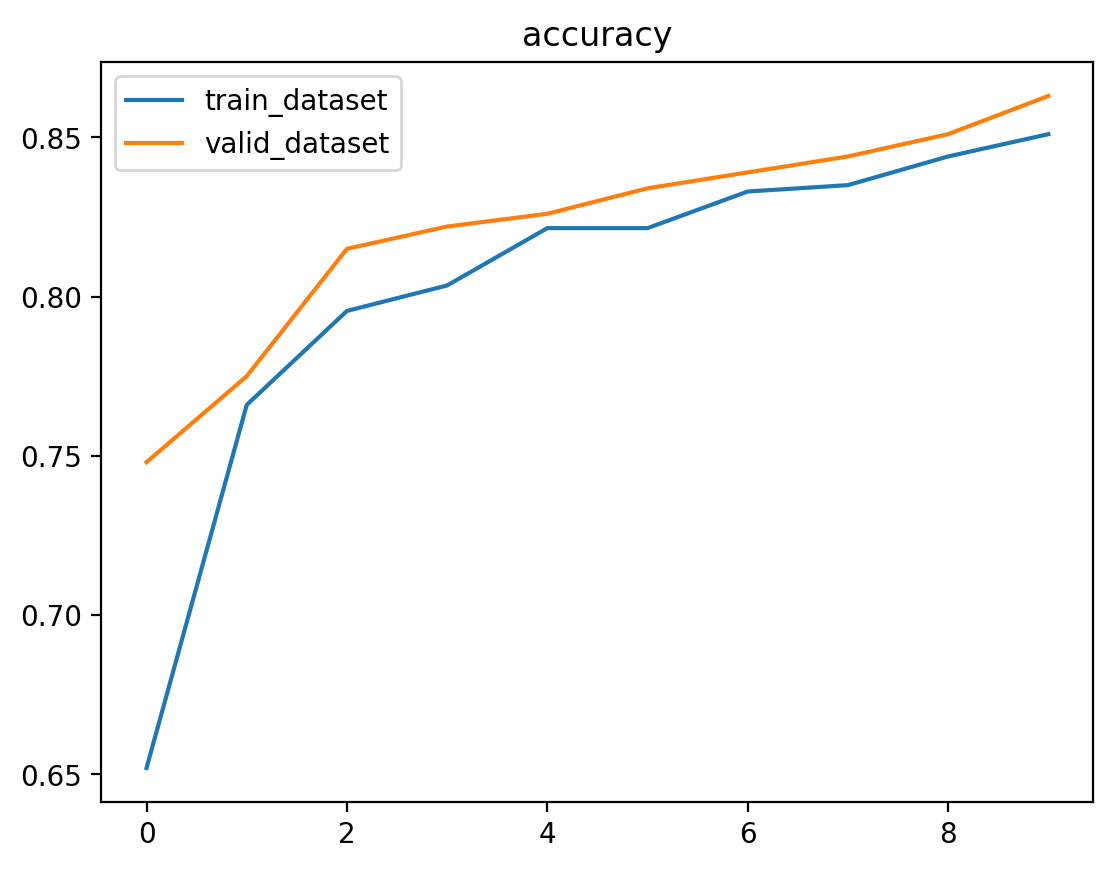

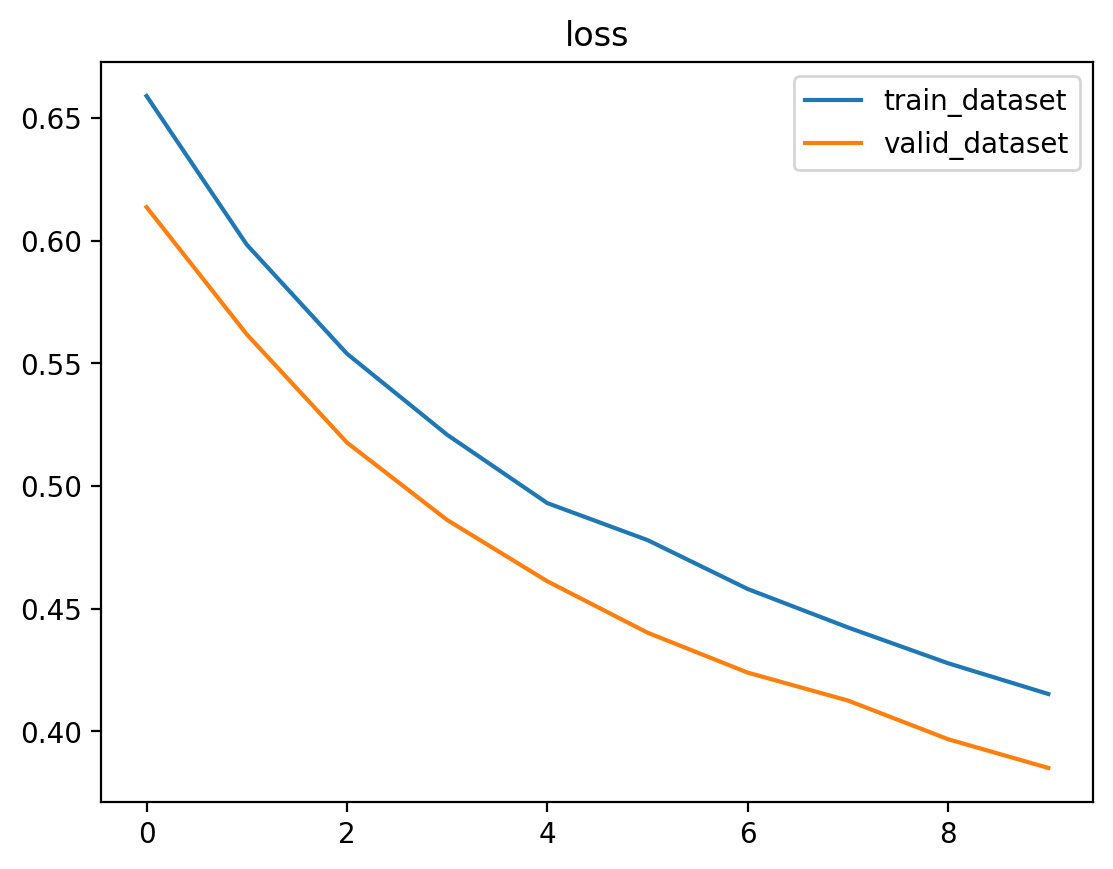

In [14]:
accuracy = history.history['accuracy']
val_accuracy = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = range(len(accuracy))

plt.plot(epochs, accuracy, label="train_dataset")
plt.plot(epochs, val_accuracy, label="valid_dataset")
plt.legend()
plt.title('accuracy')
plt.figure()


plt.plot(epochs, loss, label="train_dataset")
plt.plot(epochs, val_loss, label="valid_dataset")
plt.legend()
plt.title('loss')

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 816ms/step


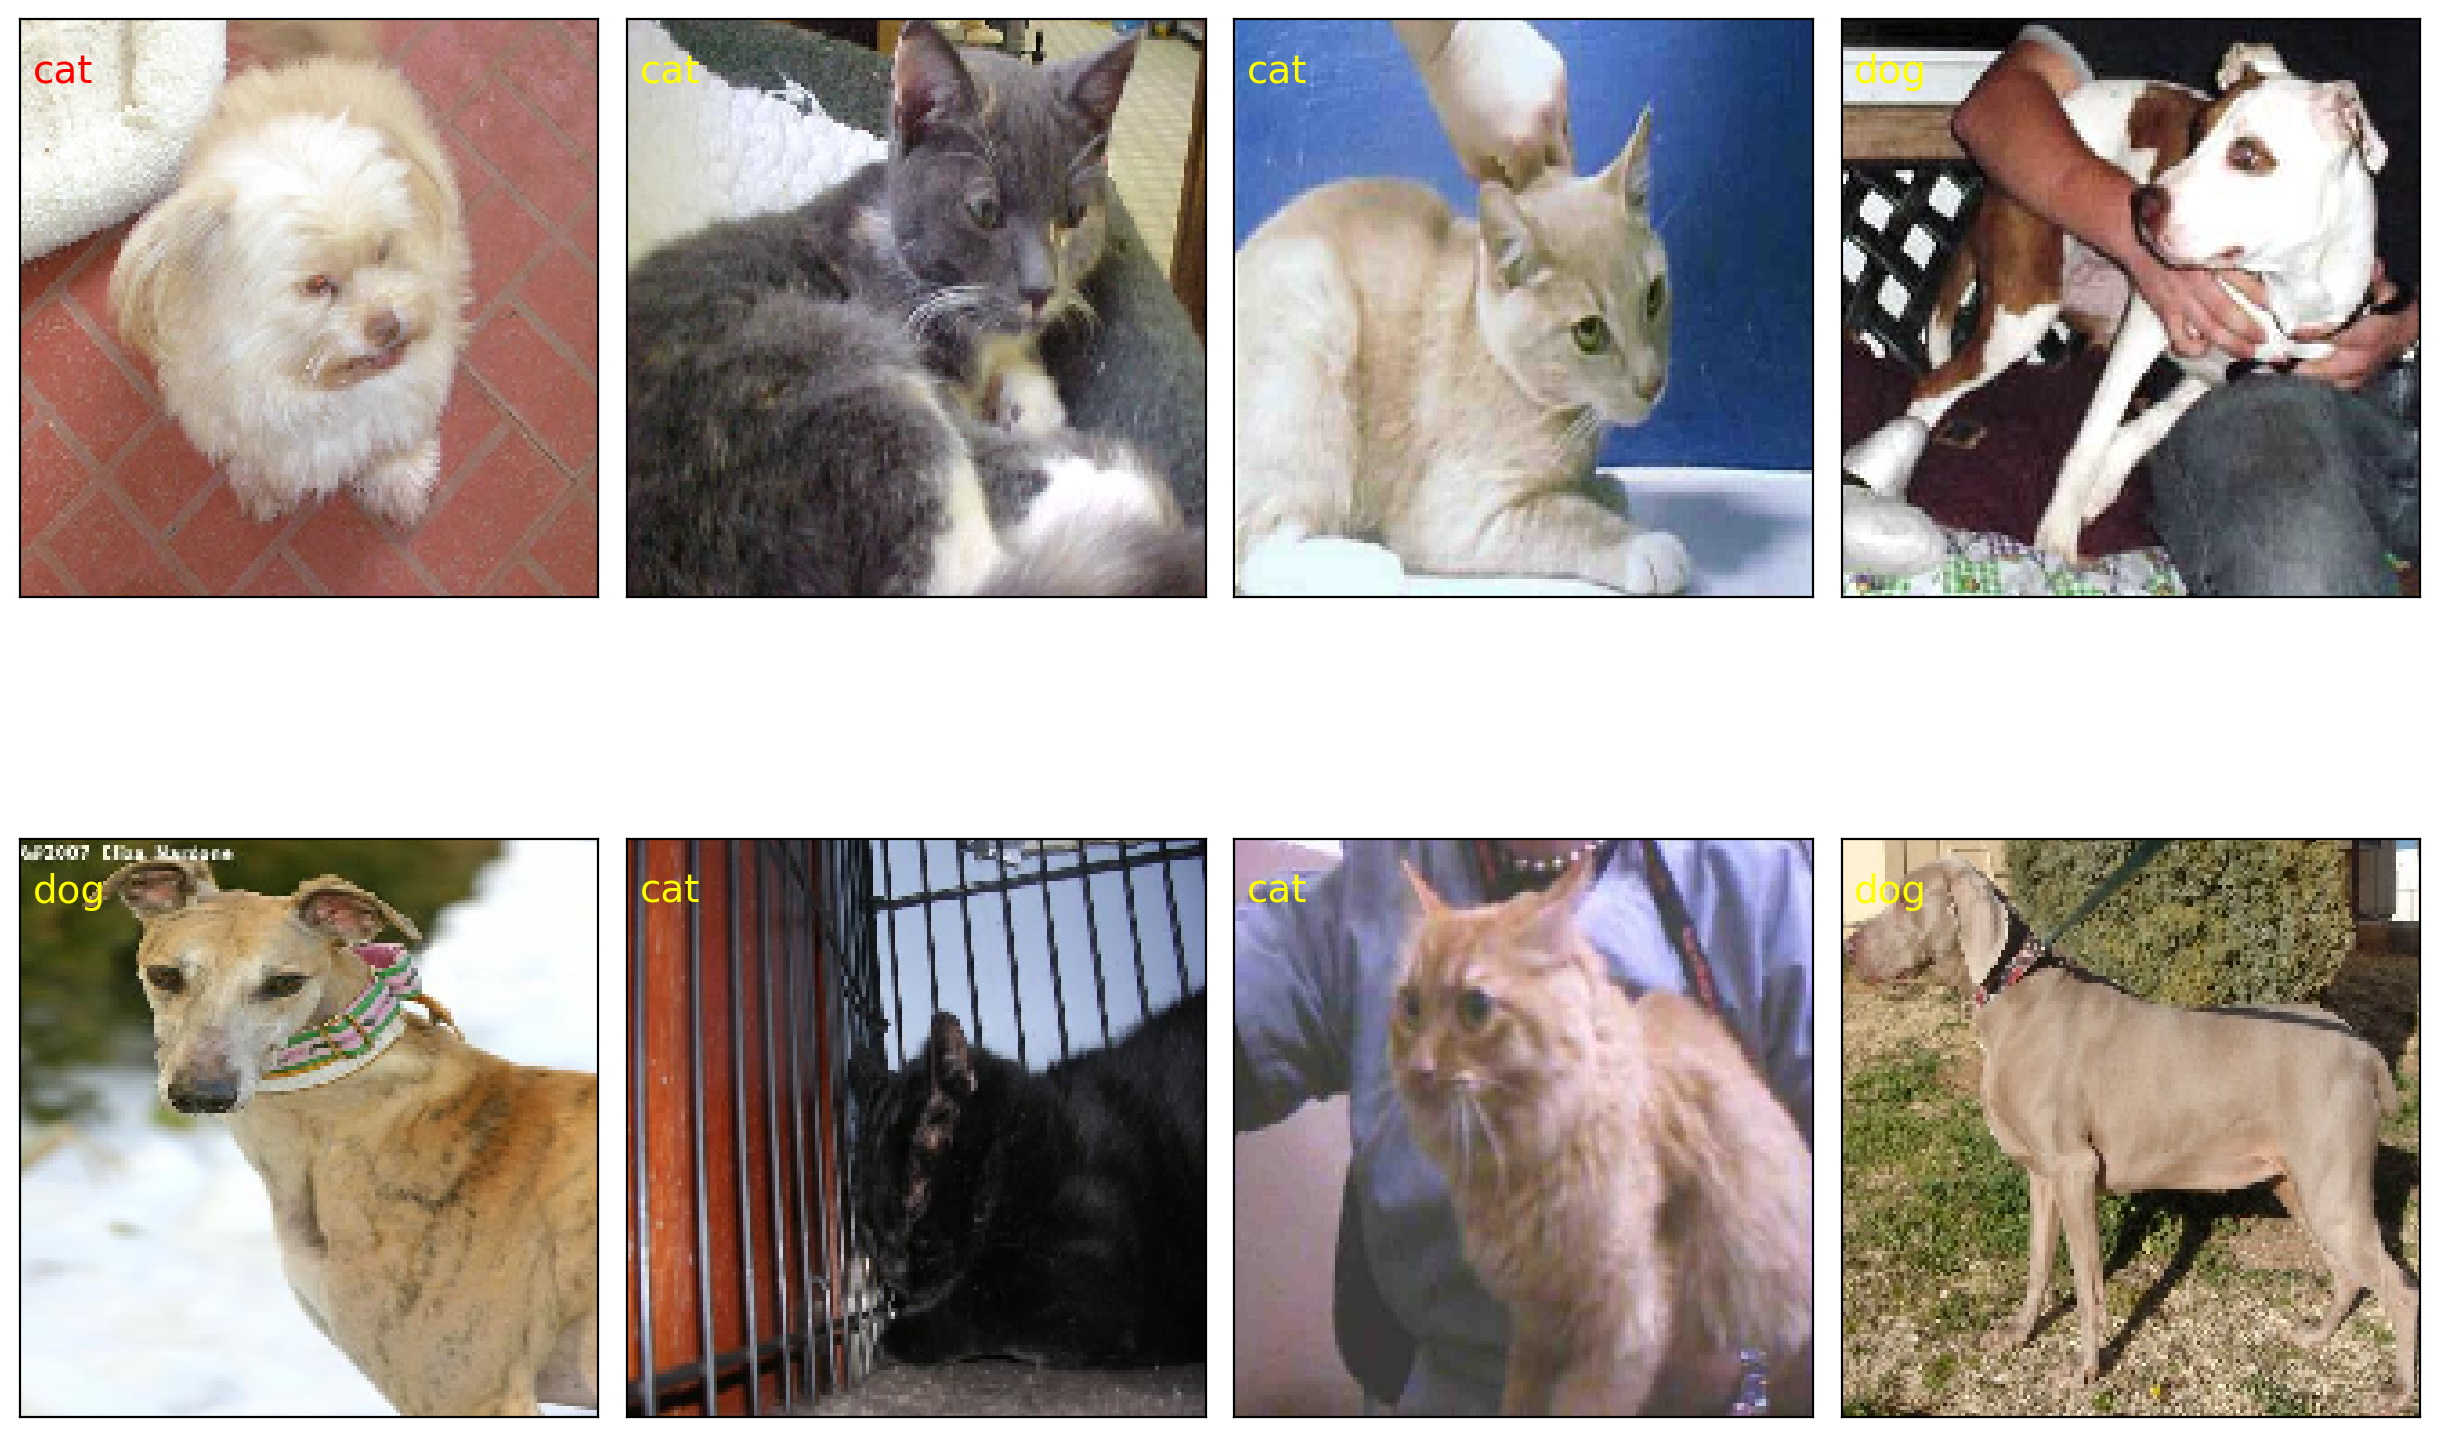

In [15]:
class_names = ['cat', 'dog']  # 클래스 이름을 정의합니다. 'cat'과 'dog' 두 개의 클래스가 있습니다.
validation, label_batch  = next(iter(valid_generator))  # 검증 데이터셋에서 다음 배치를 가져옵니다. validation은 이미지 데이터, label_batch는 해당 레이블입니다.
prediction_values = model.predict(validation)  # 모델을 사용하여 검증 데이터에 대한 예측을 수행합니다.
prediction_values = np.argmax(prediction_values, axis=1)  # 예측 결과에서 가장 높은 확률을 가진 클래스 인덱스를 추출합니다.

fig = plt.figure(figsize=(12, 8))  # 그림을 생성하고 크기를 (12, 8)로 설정합니다.
fig.subplots_adjust(left=0, right=1, bottom=0, top=1, hspace=0.05, wspace=0.05)  # 서브플롯 간의 간격을 조정합니다.


for i in range(8):
    ax = fig.add_subplot(2, 4, i + 1, xticks=[], yticks=[])
    ax.imshow(validation[i,:],cmap=plt.cm.gray_r, interpolation='nearest')
    if prediction_values[i] == np.argmax(label_batch[i]):
        ax.text(3, 17, class_names[prediction_values[i]], color='yellow', fontsize=14)
    else:
        ax.text(3, 17, class_names[prediction_values[i]], color='red', fontsize=14)

In [16]:
fe_loss, fe_acc = model.evaluate(valid_generator, verbose=0)
print(f"특성 추출 — 검증 정확도: {fe_acc:.4f}")
fe_history = history.history

특성 추출 — 검증 정확도: 0.8630


## 4.7 미세조정
VGG16을 새로 불러와 앞쪽 층은 고정하고, 마지막 블록(block5)의 일부 층과 분류기를 함께 학습합니다. 이미 학습된 가중치를 조금만 고치도록 학습률을 낮춥니다.

In [17]:
model = VGG16(include_top=False,
                 weights="imagenet")

In [18]:
print(len(model.layers))

19


In [19]:
for i,j in enumerate(model.layers):
  print(i, j.name)

0 input_layer_2
1 block1_conv1
2 block1_conv2
3 block1_pool
4 block2_conv1
5 block2_conv2
6 block2_pool
7 block3_conv1
8 block3_conv2
9 block3_conv3
10 block3_pool
11 block4_conv1
12 block4_conv2
13 block4_conv3
14 block4_pool
15 block5_conv1
16 block5_conv2
17 block5_conv3
18 block5_pool


In [20]:
model.trainable = True	# 학습 동결을 해제
for layer in model.layers[:16]:	# 0~15번 층(block5_conv1까지) 동결
  layer.trainable =  False

In [21]:
model = Sequential([model,
                    GlobalAveragePooling2D(),
                    Dense(2, activation='softmax')])
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, None, None,     │    14,714,688 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │         1,026 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,715,714 (56.14 MB)

 Trainable params: 4,720,642 (18.01 MB)

 Non-trainable params: 9,995,072 (38.13 MB)

In [22]:
model.compile(loss='binary_crossentropy',
              optimizer=tf.keras.optimizers.Adam(learning_rate = 0.0001),
              metrics=['accuracy'])

In [23]:
history=model.fit(train_generator,
          epochs=10,
          validation_data=valid_generator,
          verbose=2)

Epoch 1/10
63/63 - 27s - 432ms/step - accuracy: 0.7950 - loss: 0.4218 - val_accuracy: 0.9030 - val_loss: 0.2200
Epoch 2/10
63/63 - 19s - 306ms/step - accuracy: 0.9100 - loss: 0.2377 - val_accuracy: 0.9200 - val_loss: 0.1870
Epoch 3/10
63/63 - 19s - 305ms/step - accuracy: 0.9140 - loss: 0.2134 - val_accuracy: 0.9270 - val_loss: 0.1865
Epoch 4/10
63/63 - 19s - 302ms/step - accuracy: 0.9370 - loss: 0.1536 - val_accuracy: 0.9260 - val_loss: 0.1701
Epoch 5/10
63/63 - 19s - 300ms/step - accuracy: 0.9450 - loss: 0.1393 - val_accuracy: 0.9210 - val_loss: 0.1690
Epoch 6/10
63/63 - 19s - 303ms/step - accuracy: 0.9625 - loss: 0.1039 - val_accuracy: 0.9190 - val_loss: 0.2114
Epoch 7/10
63/63 - 19s - 298ms/step - accuracy: 0.9715 - loss: 0.0737 - val_accuracy: 0.9200 - val_loss: 0.2153
Epoch 8/10
63/63 - 19s - 301ms/step - accuracy: 0.9760 - loss: 0.0669 - val_accuracy: 0.9270 - val_loss: 0.1975
Epoch 9/10
63/63 - 19s - 298ms/step - accuracy: 0.9830 - loss: 0.0476 - val_accuracy: 0.9150 - val_loss:

Text(0.5, 1.0, 'loss')

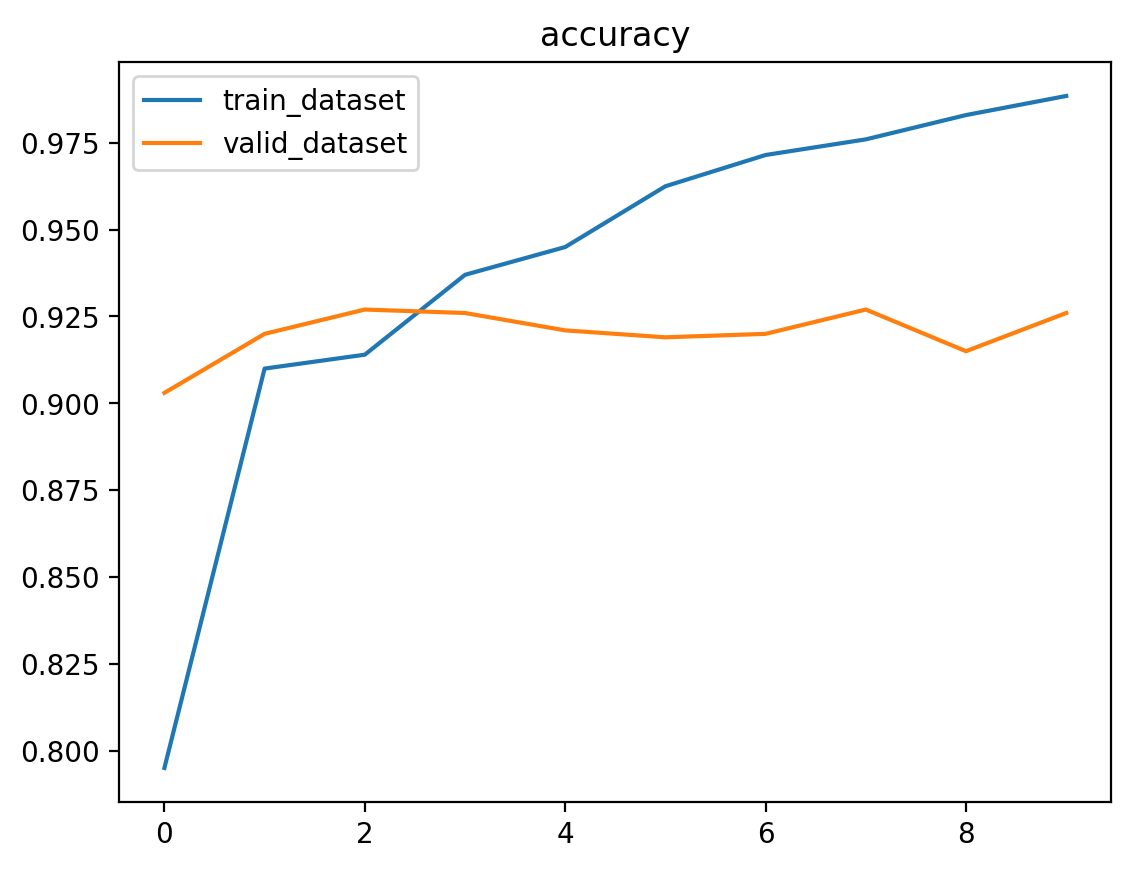

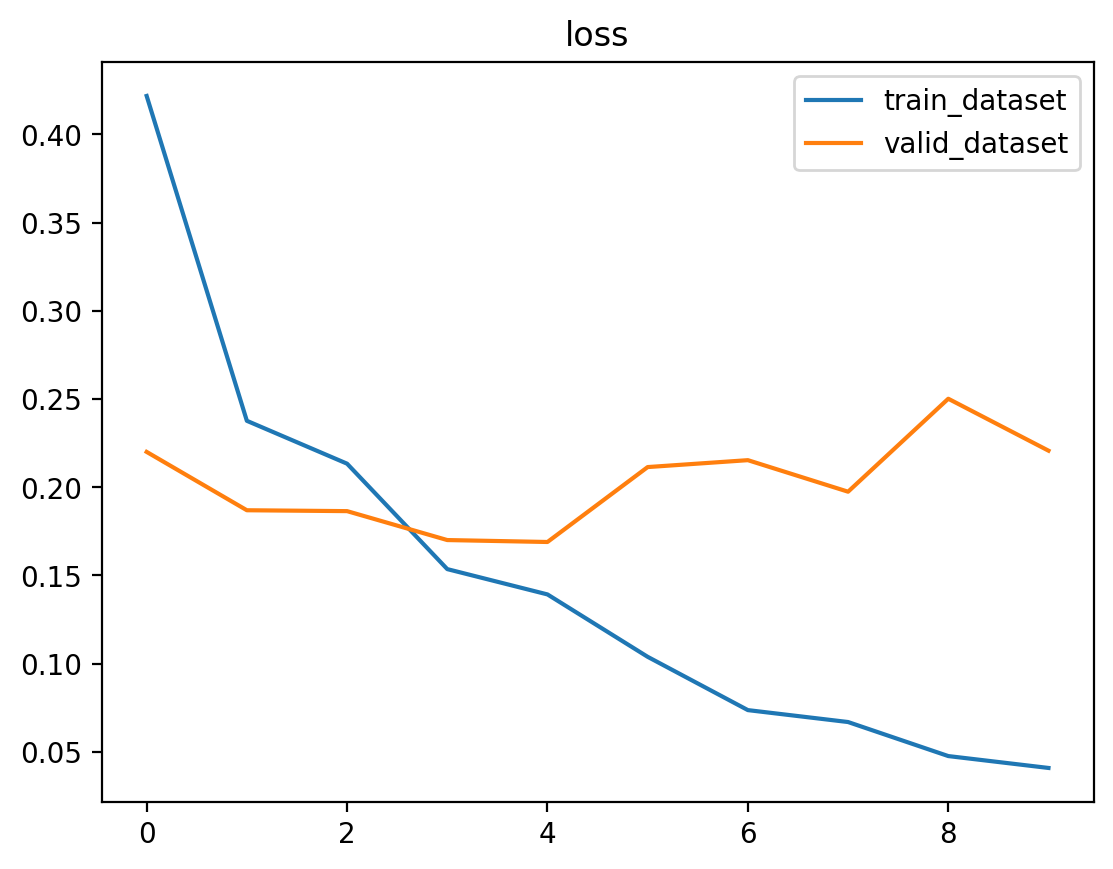

In [24]:
accuracy = history.history['accuracy']
val_accuracy = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = range(len(accuracy))

plt.plot(epochs, accuracy, label="train_dataset")
plt.plot(epochs, val_accuracy, label="valid_dataset")
plt.legend()
plt.title('accuracy')
plt.figure()


plt.plot(epochs, loss, label="train_dataset")
plt.plot(epochs, val_loss, label="valid_dataset")
plt.legend()
plt.title('loss')

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 719ms/step


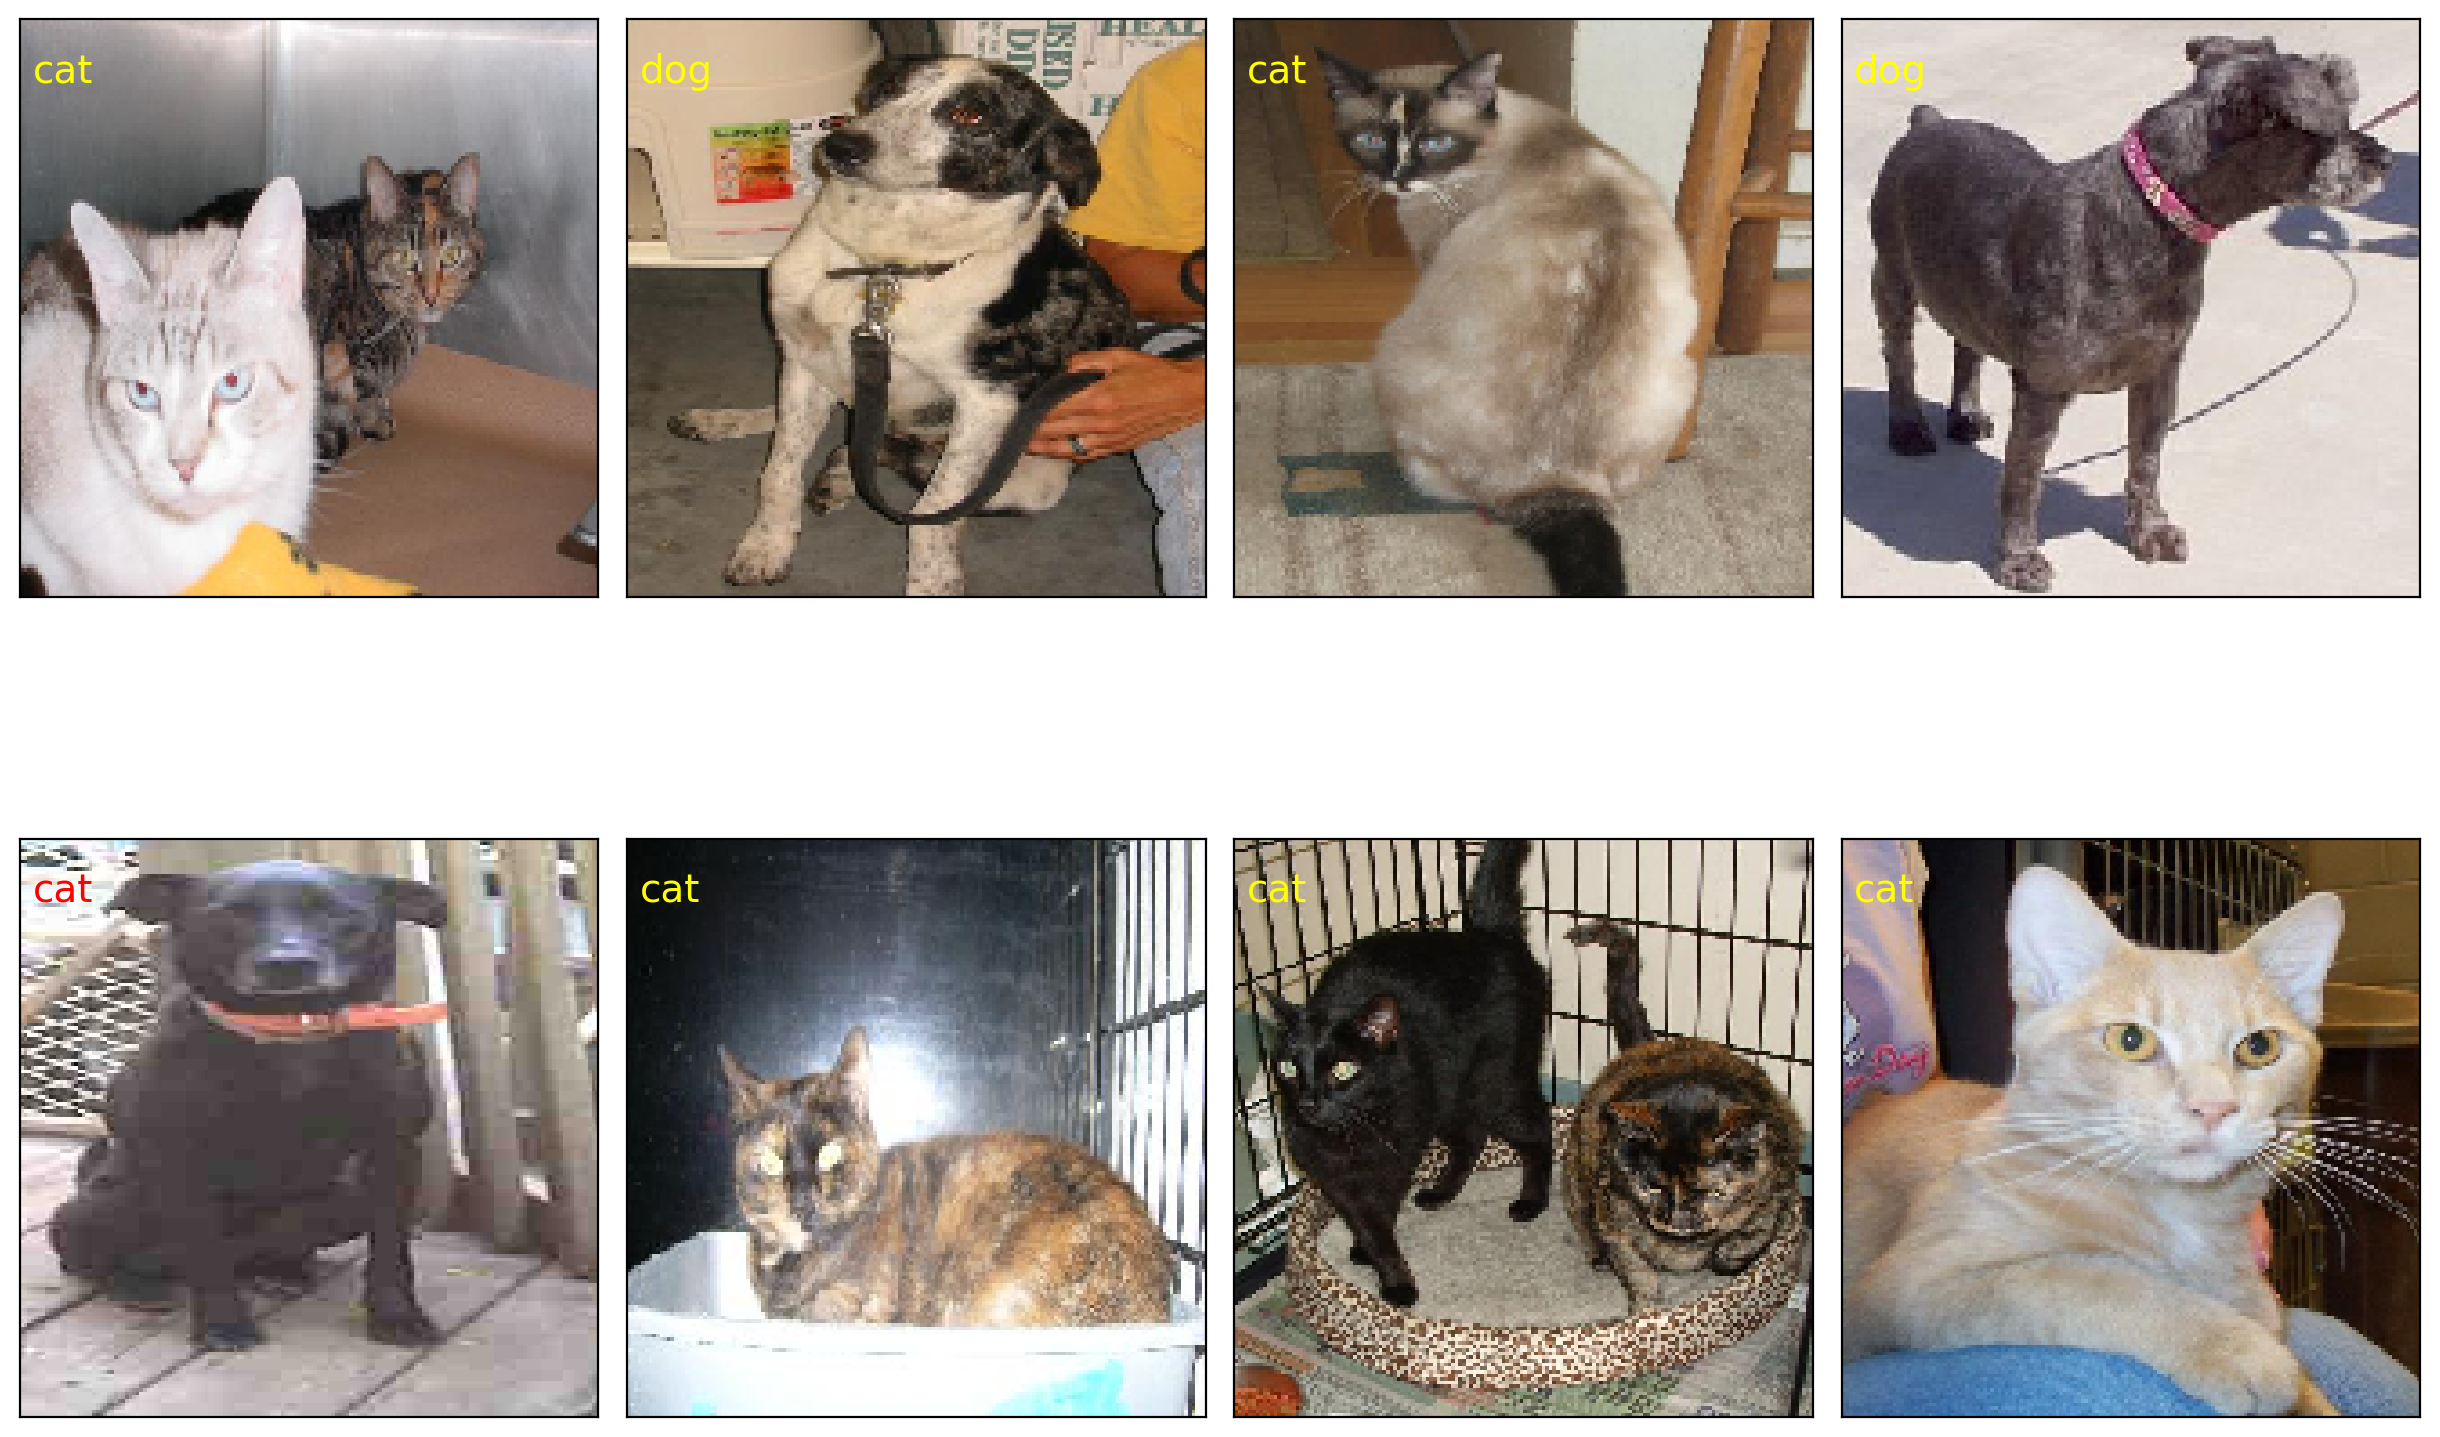

In [25]:
class_names = ['cat', 'dog']
validation, label_batch  = next(iter(valid_generator))
prediction_values = model.predict(validation)
prediction_values = np.argmax(prediction_values, axis=1)

fig = plt.figure(figsize=(12, 8))
fig.subplots_adjust(left=0, right=1, bottom=0, top=1, hspace=0.05, wspace=0.05)

for i in range(8):
    ax = fig.add_subplot(2, 4, i + 1, xticks=[], yticks=[])
    ax.imshow(validation[i,:],cmap=plt.cm.gray_r, interpolation='nearest')
    if prediction_values[i] == np.argmax(label_batch[i]):
        ax.text(3, 17, class_names[prediction_values[i]], color='yellow', fontsize=14)
    else:
        ax.text(3, 17, class_names[prediction_values[i]], color='red', fontsize=14)

In [26]:
ft_loss, ft_acc = model.evaluate(valid_generator, verbose=0)
print(f"특성 추출 — 검증 정확도: {fe_acc:.4f}")
print(f"미세조정 — 검증 정확도: {ft_acc:.4f}")
ft_history = history.history

특성 추출 — 검증 정확도: 0.8630
미세조정 — 검증 정확도: 0.9260


## 실습: 미세조정 범위와 학습률 바꿔 보기
차이가 분명히 보이도록 값을 크게 바꿔 봅니다. 예시 답안은 짧은 시간에 돌릴 수 있도록 설정마다 **한 번씩**(시드 3) 학습합니다. 결과는 실행마다 조금씩 달라지므로, 시간이 있으면 `SEEDS = [1, 2, 3]`으로 바꿔 세 번 학습한 평균과 비교해 보세요(약 50분)(책의 표 4.1이 이렇게 얻은 결과입니다).
1. **범위**: 학습률 0.0001은 그대로 두고, block5 일부(앞의 16개 층 동결)만 푼 경우와 **VGG16 전체**(동결 없음)를 푼 경우를 비교해 보세요. 학습할 파라미터 수, 검증 정확도, 학습·검증 곡선이 어떻게 다른가요?
2. **학습률**: block5 일부만 풀고 학습률을 **0.00001, 0.0001, 0.01**로 바꿔 보세요. 각각 어떤 일이 일어나나요?
3. 특성 추출 결과까지 포함해 표 하나로 정리하고, 이 데이터에 알맞은 설정을 이유와 함께 설명해 보세요.

먼저 직접 작성해 본 뒤, 아래 예시 답안과 비교해 보세요. 예시 답안은 T4 GPU에서 약 20분 걸립니다(시드 3개면 약 50분).

In [27]:
# 직접 작성해 보세요



### 예시 답안

In [28]:
def build_finetune(n_frozen, lr):
    base = VGG16(include_top=False, weights="imagenet")
    base.trainable = True
    for layer in base.layers[:n_frozen]:
        layer.trainable = False
    m = Sequential([base, GlobalAveragePooling2D(), Dense(2, activation='softmax')])
    m.compile(loss='binary_crossentropy',
              optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
              metrics=['accuracy'])
    return m

SEEDS = [3]          # 시드 3개로 평균을 내려면 [1, 2, 3] (약 50분)
runs = {}   # 설정 이름 -> 시드별 학습 기록

def run(name, n_frozen, lr):
    runs[name] = []
    for seed in SEEDS:
        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(seed)
        m = build_finetune(n_frozen, lr)
        n_params = sum(int(np.prod(w.shape)) for w in m.trainable_weights)
        h = m.fit(train_generator, epochs=10, validation_data=valid_generator, verbose=0).history
        runs[name].append(h)
        best = int(np.argmin(h['val_loss']))
        print(f"{name} | seed {seed} | 학습 파라미터 {n_params:,} | "
              f"10에포크 뒤 {h['val_accuracy'][-1]:.4f} | 검증 손실 최소 {best+1}에포크 {h['val_accuracy'][best]:.4f}")
        print("   val_accuracy:", " ".join(f"{v:.3f}" for v in h['val_accuracy']))
        print("   val_loss    :", " ".join(f"{v:.3f}" for v in h['val_loss']))
        print("   accuracy    :", " ".join(f"{v:.3f}" for v in h['accuracy']))
        print("   loss        :", " ".join(f"{v:.3f}" for v in h['loss']))

LABEL = {'block5 일부, lr=1e-4': 'block5, lr=1e-4', '전체, lr=1e-4': 'all layers, lr=1e-4',
         'block5 일부, lr=1e-5': 'block5, lr=1e-5', 'block5 일부, lr=1e-2': 'block5, lr=1e-2'}   # 그래프 범례용 영어 이름

def plot_runs(names, title):
    plt.figure(figsize=(10, 3.5))
    for k, key in enumerate(['val_loss', 'val_accuracy']):
        plt.subplot(1, 2, k + 1)
        for name in names:
            v = np.array([h[key] for h in runs[name]]); ep = range(1, v.shape[1] + 1)
            line, = plt.plot(ep, v.mean(0), label=LABEL[name])
            plt.fill_between(ep, v.min(0), v.max(0), color=line.get_color(), alpha=0.2)
        plt.title(title + ' ' + key); plt.xlabel('epoch'); plt.legend()
    plt.show()

block5 일부, lr=1e-4 | seed 3 | 학습 파라미터 4,720,642 | 10에포크 뒤 0.9230 | 검증 손실 최소 6에포크 0.9250
   val_accuracy: 0.878 0.901 0.922 0.925 0.924 0.925 0.926 0.927 0.928 0.923
   val_loss    : 0.299 0.228 0.192 0.201 0.183 0.173 0.177 0.184 0.195 0.202
   accuracy    : 0.787 0.883 0.922 0.933 0.938 0.959 0.966 0.980 0.990 0.986
   loss        : 0.440 0.271 0.184 0.171 0.152 0.101 0.092 0.060 0.041 0.042
전체, lr=1e-4 | seed 3 | 학습 파라미터 14,715,714 | 10에포크 뒤 0.9440 | 검증 손실 최소 9에포크 0.9450
   val_accuracy: 0.848 0.921 0.907 0.778 0.936 0.915 0.941 0.907 0.945 0.944
   val_loss    : 0.356 0.194 0.208 0.459 0.158 0.178 0.142 0.269 0.119 0.181
   accuracy    : 0.628 0.876 0.928 0.938 0.958 0.971 0.981 0.986 0.973 0.983
   loss        : 0.627 0.294 0.186 0.163 0.115 0.074 0.059 0.038 0.068 0.043


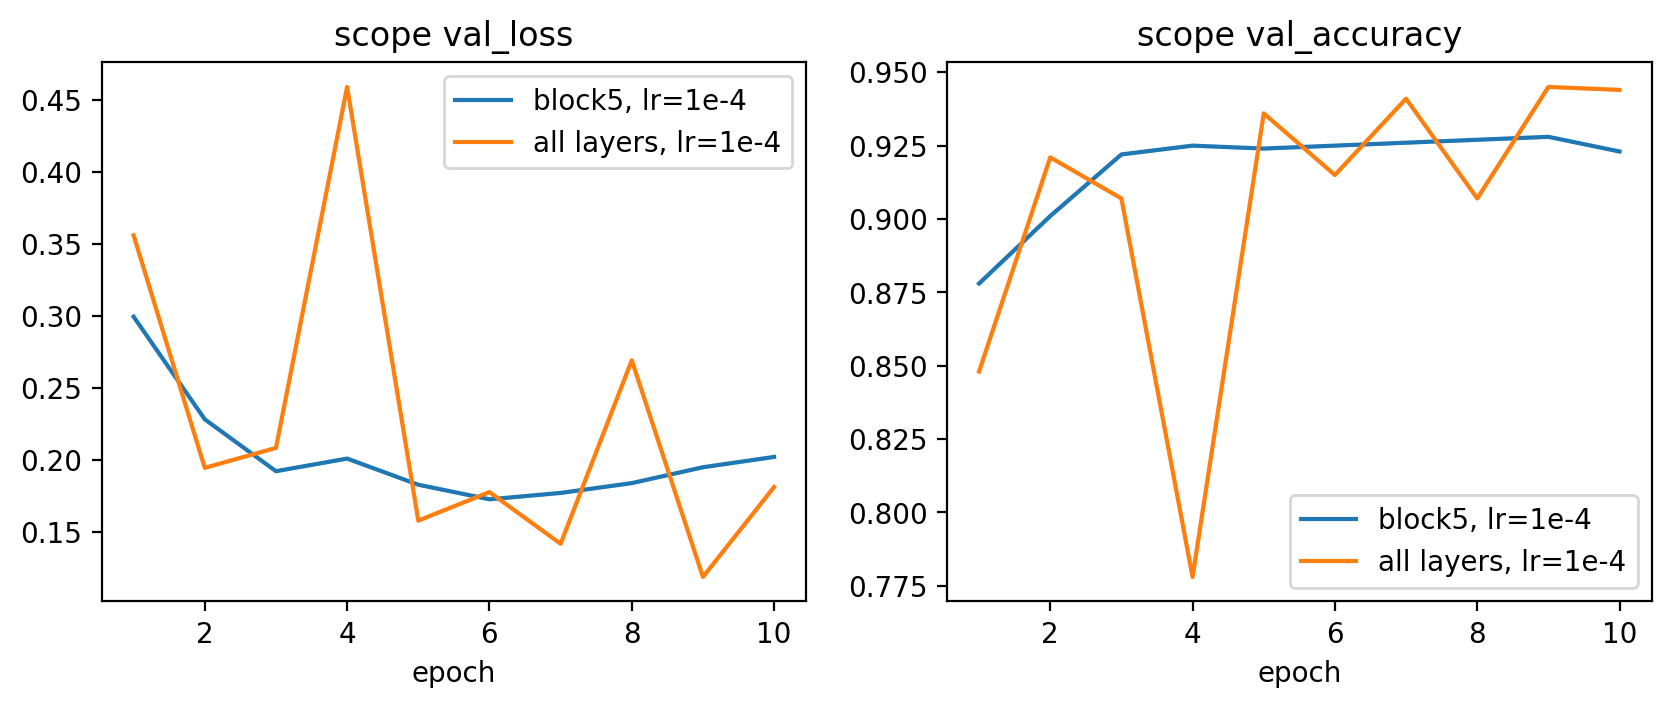

In [29]:
# 1. 범위: block5 일부 vs 전체 (학습률 0.0001)
run('block5 일부, lr=1e-4', 16, 1e-4)
run('전체, lr=1e-4', 0, 1e-4)
plot_runs(['block5 일부, lr=1e-4', '전체, lr=1e-4'], 'scope')

block5 일부, lr=1e-5 | seed 3 | 학습 파라미터 4,720,642 | 10에포크 뒤 0.9060 | 검증 손실 최소 10에포크 0.9060
   val_accuracy: 0.825 0.838 0.871 0.895 0.897 0.906 0.906 0.907 0.907 0.906
   val_loss    : 0.583 0.444 0.333 0.281 0.265 0.239 0.232 0.219 0.212 0.207
   accuracy    : 0.654 0.820 0.850 0.868 0.893 0.896 0.900 0.905 0.919 0.926
   loss        : 0.657 0.530 0.411 0.341 0.291 0.267 0.242 0.227 0.213 0.203
block5 일부, lr=1e-2 | seed 3 | 학습 파라미터 4,720,642 | 10에포크 뒤 0.9200 | 검증 손실 최소 4에포크 0.9240
   val_accuracy: 0.889 0.917 0.914 0.924 0.904 0.910 0.912 0.894 0.926 0.920
   val_loss    : 0.303 0.226 0.225 0.191 0.256 0.284 0.233 0.239 0.208 0.295
   accuracy    : 0.687 0.878 0.897 0.929 0.919 0.926 0.944 0.934 0.959 0.968
   loss        : 13.205 0.278 0.234 0.166 0.184 0.183 0.154 0.164 0.113 0.078


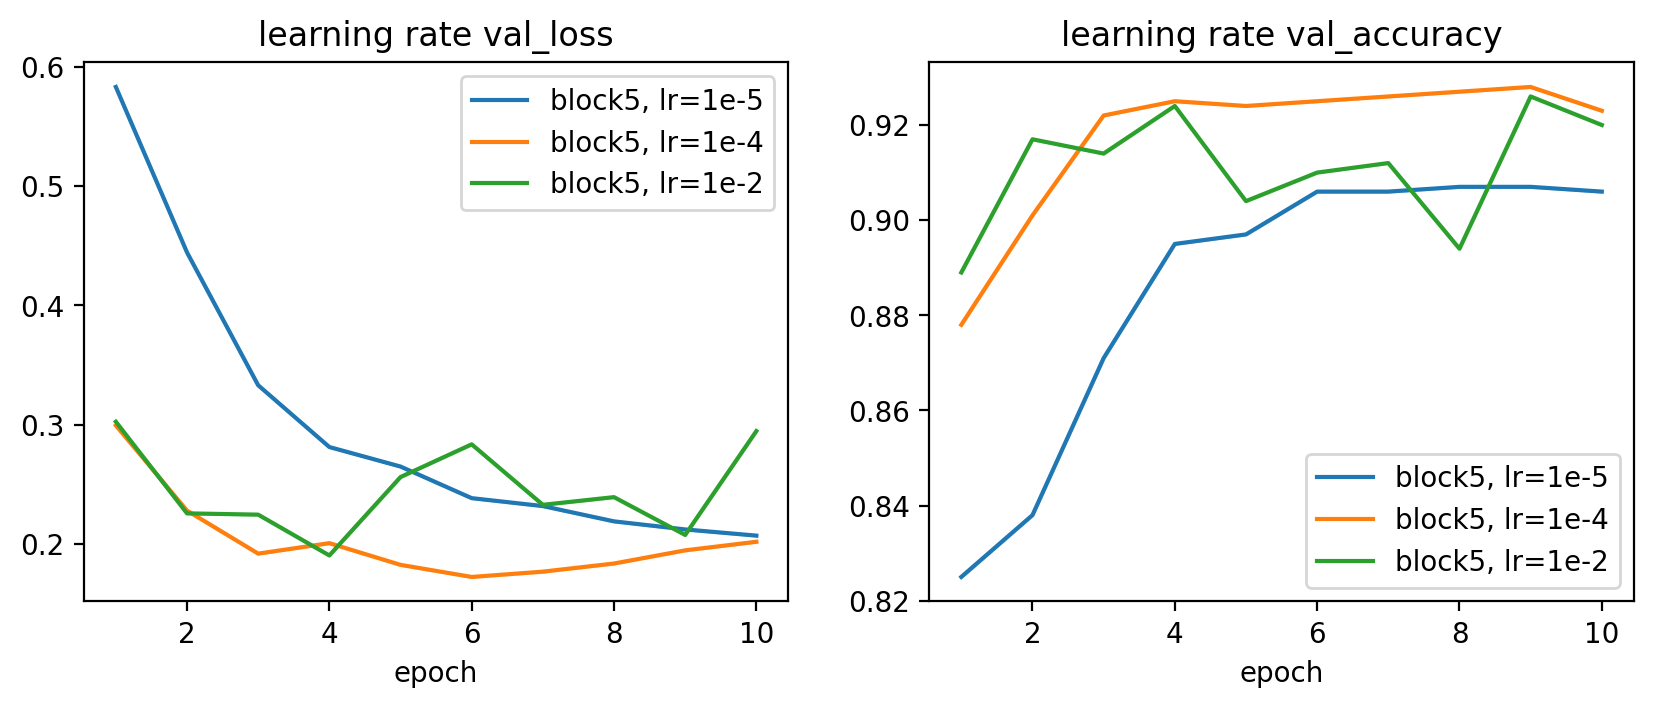

In [30]:
# 2. 학습률: 0.00001 / 0.0001 / 0.01 (block5 일부)
run('block5 일부, lr=1e-5', 16, 1e-5)
run('block5 일부, lr=1e-2', 16, 1e-2)
plot_runs(['block5 일부, lr=1e-5', 'block5 일부, lr=1e-4', 'block5 일부, lr=1e-2'], 'learning rate')

In [31]:
# 3. 결과 정리 (시드가 여러 개면 평균, 괄호 안은 최솟값~최댓값)
print(f"특성 추출(분류기만, lr=1e-3): {fe_acc:.4f}  (위에서 한 번 실행)")
for name, hs in runs.items():
    last = np.array([h['val_accuracy'][-1] for h in hs])
    best = np.array([h['val_accuracy'][int(np.argmin(h['val_loss']))] for h in hs])
    print(f"{name:<22} 10에포크 뒤 {last.mean():.4f} ({last.min():.3f}~{last.max():.3f})"
          f" | 검증 손실 최소 시점 {best.mean():.4f} ({best.min():.3f}~{best.max():.3f})")

특성 추출(분류기만, lr=1e-3): 0.8630  (위에서 한 번 실행)
block5 일부, lr=1e-4     10에포크 뒤 0.9230 (0.923~0.923) | 검증 손실 최소 시점 0.9250 (0.925~0.925)
전체, lr=1e-4            10에포크 뒤 0.9440 (0.944~0.944) | 검증 손실 최소 시점 0.9450 (0.945~0.945)
block5 일부, lr=1e-5     10에포크 뒤 0.9060 (0.906~0.906) | 검증 손실 최소 시점 0.9060 (0.906~0.906)
block5 일부, lr=1e-2     10에포크 뒤 0.9200 (0.920~0.920) | 검증 손실 최소 시점 0.9240 (0.924~0.924)


**결과를 읽을 때 주의할 점**: 학습률 0.01은 첫 에포크의 학습 손실(`loss`)이 10이 넘게 치솟습니다(0.0001일 때는 약 0.4). 그 뒤 회복해 정확도만 보면 괜찮아 보일 때도 있지만, 시드를 바꿔 여러 번 해 보면 사전학습된 특징이 망가져 정확도 50%(사실상 한 범주로만 답함)에 머무는 경우가 나옵니다(책의 표 4.1에서는 3번 중 1번). `SEEDS = [1, 2, 3]`으로 바꿔 직접 확인해 보세요.